# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북은 `book/chapters/ch07_visualization.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 그래프를 많이 그리는 것이 아니라, 분석 질문에 맞는 그래프를 고르고, 그래프가 보여주는 것과 보여주지 않는 것을 구분하는 것입니다.


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 이 노트북은 5장에서 만든 `data/processed/*_clean.csv` 파일을 사용합니다.
- 전처리 파일이 없다면 먼저 `python scripts/preprocess_data.py`를 실행하세요.
- 그래프 파일은 `reports/figures/` 폴더에 저장합니다.
- 그래프 해석에서는 관찰과 원인 가설을 반드시 구분합니다.


## 1. 시각화는 분석 질문에서 시작된다

좋은 시각화는 그래프 종류를 많이 아는 데서 시작하지 않습니다. 먼저 어떤 질문에 답하려는지 정해야 합니다.

| 분석 목적 | 적합한 그래프 | 예시 질문 |
|---|---|---|
| 범주별 크기 비교 | 막대그래프 | 카테고리별 매출은 어떻게 다른가? |
| 시간 흐름 확인 | 선 그래프 | 월별 매출은 어떻게 변하는가? |
| 값의 분포 확인 | 히스토그램 | 상품 가격은 어떤 범위에 몰려 있는가? |
| 두 변수 관계 확인 | 산점도 | 가격과 판매 수량은 관계가 있는가? |
| 상위 항목 비교 | 가로 막대그래프 | 구매 금액 상위 고객은 누구인가? |
| 비율 비교 | 막대그래프 또는 파이 차트 | 주문 상태별 비중은 어떻게 되는가? |


## 2. 이번 장에서 만들 그래프

이번 장에서는 6장 EDA에서 만든 질문을 그래프로 표현합니다.

| 시각화 질문 | 사용할 데이터 | 그래프 |
|---|---|---|
| 카테고리별 매출은 어떻게 다른가? | `category_sales` | 막대그래프 |
| 월별 매출은 어떻게 변하는가? | `monthly_sales` | 선 그래프 |
| 상품 가격은 어떤 구간에 몰려 있는가? | `products` | 히스토그램 |
| 상품 가격과 판매 수량은 관계가 있는가? | `product_sales` | 산점도 |
| 구매 금액 상위 고객은 누구인가? | `customer_sales` | 가로 막대그래프 |
| 주문 상태별 주문 수는 어떻게 다른가? | `orders` | 막대그래프 |


## 3. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

CURRENT_DIR = Path.cwd().resolve()
# 프로젝트 루트, chapter07, notebooks 어디에서 열더라도 processed 파일을 찾는다.
search_roots = [CURRENT_DIR, *CURRENT_DIR.parents]
search_roots = [p for p in search_roots if str(p) != '/']
found = next((p for p in search_roots if all((p/'data'/'processed'/f).exists() for f in
              ['customers_clean.csv','products_clean.csv','orders_clean.csv','order_items_clean.csv'])), None)
if found is None:
    found = next((p for p in search_roots if all((p/f).exists() for f in
                  ['customers_clean.csv','products_clean.csv','orders_clean.csv','order_items_clean.csv'])), None)
if found is None:
    raise FileNotFoundError('processed CSV 4개를 찾지 못했습니다. 프로젝트 루트의 data/processed/ 폴더에 넣어 주세요.')
PROJECT_ROOT = found
PROCESSED_DIR = PROJECT_ROOT/'data'/'processed' if (PROJECT_ROOT/'data'/'processed'/'orders_clean.csv').exists() else PROJECT_ROOT
REPORT_DIR = PROJECT_ROOT/'reports'
FIGURE_DIR = REPORT_DIR/'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print('현재 실행 위치:', CURRENT_DIR)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('그래프 저장 폴더:', FIGURE_DIR)

현재 실행 위치: /mnt/data/chapter07_실행패키지
전처리 데이터 폴더: /mnt/data/chapter07_실행패키지/data/processed
그래프 저장 폴더: /mnt/data/chapter07_실행패키지/reports/figures


## 4. 한글 폰트 설정

matplotlib에서 한글 제목이나 축 이름을 사용하면 글자가 깨질 수 있습니다. Windows 환경에서는 보통 `Malgun Gothic`을 사용합니다. Mac은 `AppleGothic`, Linux는 `NanumGothic`을 사용할 수 있습니다.


In [2]:
# 현재 환경에 설치된 글꼴 중 한글을 지원하는 글꼴을 사용한다.
from matplotlib import font_manager
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
for candidate in ['Malgun Gothic','AppleGothic','NanumGothic','NanumSquare','UnDotum','Noto Sans CJK KR','DejaVu Sans']:
    if candidate in installed_fonts:
        plt.rcParams['font.family'] = candidate
        break
plt.rcParams['axes.unicode_minus'] = False
money_formatter = FuncFormatter(lambda value, pos: f'{value:,.0f}')
print('설정된 글꼴:', plt.rcParams['font.family'])

설정된 글꼴: ['NanumGothic']


## 5. 전처리 데이터 불러오기

7장은 5장에서 저장한 전처리 데이터를 사용합니다. 파일이 없다면 터미널에서 `python scripts/preprocess_data.py`를 먼저 실행하세요.


In [3]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    for path in missing_files:
        print('누락 파일:', path)
    raise FileNotFoundError('전처리 파일이 없습니다. 먼저 python scripts/preprocess_data.py 를 실행하세요.')

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('전처리 데이터 불러오기 완료')


전처리 데이터 불러오기 완료


In [4]:
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
orders['order_month'] = orders['order_date'].dt.strftime('%Y-%m')
for col in ['price']:
    products[col] = pd.to_numeric(products[col], errors='coerce')
for col in ['quantity','unit_price','line_total']:
    if col in order_items:
        order_items[col] = pd.to_numeric(order_items[col], errors='coerce')
order_items['line_total'] = order_items['quantity'] * order_items['unit_price']
print('customers:', customers.shape, 'products:', products.shape)
print('orders:', orders.shape, 'order_items:', order_items.shape)
print('주문일 범위:', orders['order_date'].min().date(), '~', orders['order_date'].max().date())

customers: (150, 6) products: (100, 4)
orders: (300, 7) order_items: (764, 6)
주문일 범위: 2025-09-12 ~ 2026-09-11


## 6. 시각화를 위한 집계 데이터 만들기

그래프를 그리기 전에 필요한 집계표를 만듭니다. 대부분의 시각화는 원본 데이터를 바로 그리기보다, 질문에 맞게 요약한 표를 만든 뒤 그립니다.


In [5]:
# 주문 상태는 상세에 없으므로 먼저 주문 정보와 연결하고 완료 주문만 남긴다.
status_items = order_items.merge(
    orders[['order_id','customer_id','order_date','order_month','order_status']],
    on='order_id', how='left', validate='many_to_one', indicator=True,
)
assert len(status_items) == len(order_items), '주문 병합 후 상세 행 수가 변했습니다.'
assert (status_items['_merge'] == 'both').all(), '주문 정보와 매칭되지 않은 상세가 있습니다.'
completed_items = status_items.loc[status_items['order_status'].eq('completed')].drop(columns='_merge').copy()
sales_items = completed_items.merge(products,on='product_id',how='left',validate='many_to_one',indicator=True)
assert len(sales_items) == len(completed_items)
assert (sales_items['_merge'] == 'both').all(), '상품 정보 미매칭이 있습니다.'
sales_items = sales_items.drop(columns='_merge')
source_total = int(completed_items['line_total'].sum())
print('전체 상세 행:', len(order_items), '완료 주문 상세:', len(completed_items))
print('완료 주문 수:', completed_items['order_id'].nunique())
print('완료 주문 기준 금액:', f'{source_total:,}', '원')
sales_items[['order_id','product_id','category','quantity','line_total']].head()

전체 상세 행: 764 완료 주문 상세: 474
완료 주문 수: 184
완료 주문 기준 금액: 148,990,000 원


,order_id,product_id,category,quantity,line_total
0,1,100,도서,3,306000
1,1,87,도서,5,125000
2,1,7,도서,3,426000
3,1,9,스포츠,3,579000
4,6,83,전자기기,3,72000


In [6]:
category_sales = (
    sales_items.groupby('category', as_index=False, dropna=False)
    .agg(total_quantity=('quantity','sum'),total_sales=('line_total','sum'),order_count=('order_id','nunique'))
    .sort_values('total_sales',ascending=False).reset_index(drop=True)
)
category_sales['sales_ratio'] = category_sales['total_sales'] / source_total * 100
assert np.isclose(category_sales['total_sales'].sum(),source_total)
category_sales

,category,total_quantity,total_sales,order_count,sales_ratio
0,스포츠,295,31743000,85,21.305457
1,전자기기,259,26400000,60,17.719310
2,생활용품,272,23915000,65,16.051413
3,뷰티,223,23383000,65,15.694342
4,식품,133,16573000,36,11.123565
5,도서,149,16389000,52,11.000067
6,패션,111,10587000,33,7.105846


In [7]:
order_sales = completed_items.copy()
assert order_sales['order_date'].notna().all(), '완료 주문 날짜 변환에 실패했습니다.'
monthly_sales = (
    order_sales.groupby('order_month',as_index=False)
    .agg(total_sales=('line_total','sum'),order_count=('order_id','nunique'))
    .sort_values('order_month').reset_index(drop=True)
)
monthly_sales['avg_order_value'] = monthly_sales['total_sales'] / monthly_sales['order_count']
assert np.isclose(monthly_sales['total_sales'].sum(), source_total)
monthly_sales

,order_month,total_sales,order_count,avg_order_value
0,2025-09,3565000,6,5.941667e+05
1,2025-10,17925000,20,8.962500e+05
2,2025-11,9151000,11,8.319091e+05
3,2025-12,24278000,25,9.711200e+05
4,2026-01,11339000,15,7.559333e+05
5,2026-02,6939000,9,7.710000e+05
6,2026-03,17700000,23,7.695652e+05
7,2026-04,13250000,20,6.625000e+05
8,2026-05,13135000,14,9.382143e+05
9,2026-06,15713000,20,7.856500e+05


In [8]:
# 전체 상품 100개를 기준으로 미판매 상품은 completed_quantity=0으로 처리한다.
product_agg = sales_items.groupby('product_id',as_index=False).agg(
    completed_quantity=('quantity','sum'),total_sales=('line_total','sum'))
product_sales = products.merge(product_agg,on='product_id',how='left',validate='one_to_one')
product_sales[['completed_quantity','total_sales']] = product_sales[['completed_quantity','total_sales']].fillna(0)
assert product_sales['completed_quantity'].sum() == completed_items['quantity'].sum()
product_sales.head()

,product_id,product_name,category,price,completed_quantity,total_sales
0,1,전자기기 상품 001,전자기기,160000,4.0,640000.0
1,2,도서 상품 002,도서,34000,6.0,204000.0
2,3,전자기기 상품 003,전자기기,152000,13.0,1976000.0
3,4,생활용품 상품 004,생활용품,70000,14.0,980000.0
4,5,식품 상품 005,식품,186000,6.0,1116000.0


In [9]:
# 고객 개인정보(name)는 결합하지 않고 집계에도 사용하지 않는다.
customer_sales_base = order_sales.merge(
    customers[['customer_id','city']],on='customer_id',how='left',validate='many_to_one',indicator=True)
assert len(customer_sales_base) == len(order_sales)
assert (customer_sales_base['_merge']=='both').all()
customer_sales = (
    customer_sales_base.groupby(['customer_id','city'],as_index=False,dropna=False)
    .agg(order_count=('order_id','nunique'),total_sales=('line_total','sum'))
    .sort_values('total_sales',ascending=False).reset_index(drop=True)
)
customer_sales['avg_order_value']=customer_sales['total_sales']/customer_sales['order_count']
assert np.isclose(customer_sales['total_sales'].sum(),source_total)
customer_sales.head()

,customer_id,city,order_count,total_sales,avg_order_value
0,117,성남,5,4100000,820000.0
1,102,고양,4,3996000,999000.0
2,83,수원,4,3880000,970000.0
3,30,서울,5,3590000,718000.0
4,40,서울,4,3523000,880750.0


In [10]:
order_status = orders['order_status'].value_counts(dropna=False).reset_index()
order_status.columns = ['order_status', 'order_count']
order_status


,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


## 7. 카테고리별 매출 막대그래프

카테고리별 매출은 범주별 크기 비교이므로 막대그래프가 적합합니다. 그래프는 화면에 표시하고 동시에 PNG 파일로 저장합니다.


해석 예시:

> 관찰: 카테고리별 매출 크기가 서로 다르게 나타납니다.
> 가설: 매출 차이는 판매 수량 또는 평균 단가 차이에서 비롯되었을 수 있습니다.
> 추가 분석: 카테고리별 판매 수량과 평균 단가를 함께 확인해야 합니다.


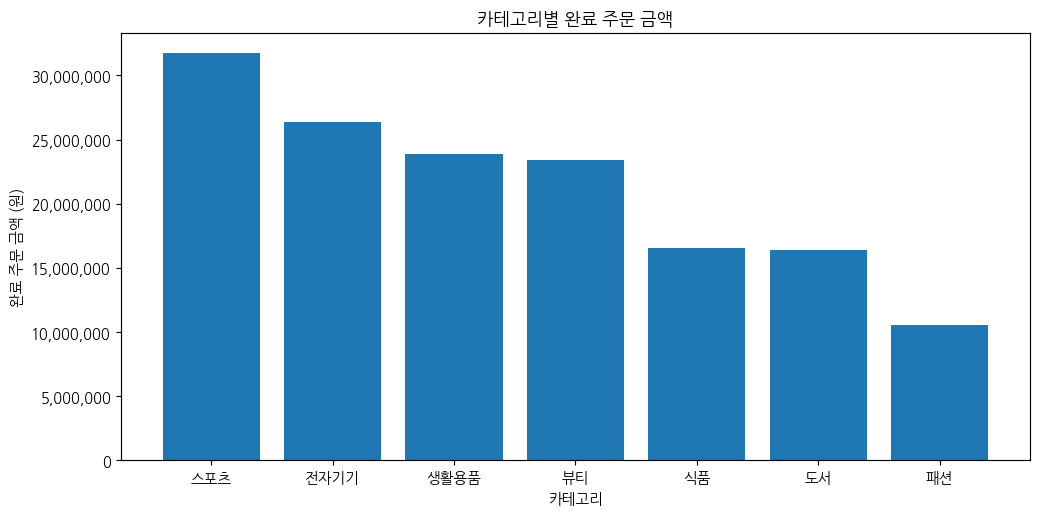

In [11]:
fig, ax = plt.subplots(figsize=(10,5))
ax.bar(category_sales['category'],category_sales['total_sales'])
ax.set(title='카테고리별 완료 주문 금액',xlabel='카테고리',ylabel='완료 주문 금액 (원)')
ax.yaxis.set_major_formatter(money_formatter)
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'ch07_category_sales_bar.png',dpi=140,bbox_inches='tight')
plt.show()

## 8. 월별 매출 선 그래프

월별 매출은 시간 흐름을 보는 문제이므로 선 그래프가 적합합니다. x축 순서가 월 순서대로 정렬되어 있어야 합니다.


월별 매출이 증가하거나 감소해도 그 원인을 바로 단정하면 안 됩니다. 주문 수, 평균 주문 금액, 프로모션 여부, 특정 카테고리 매출 변화를 추가로 확인해야 합니다.


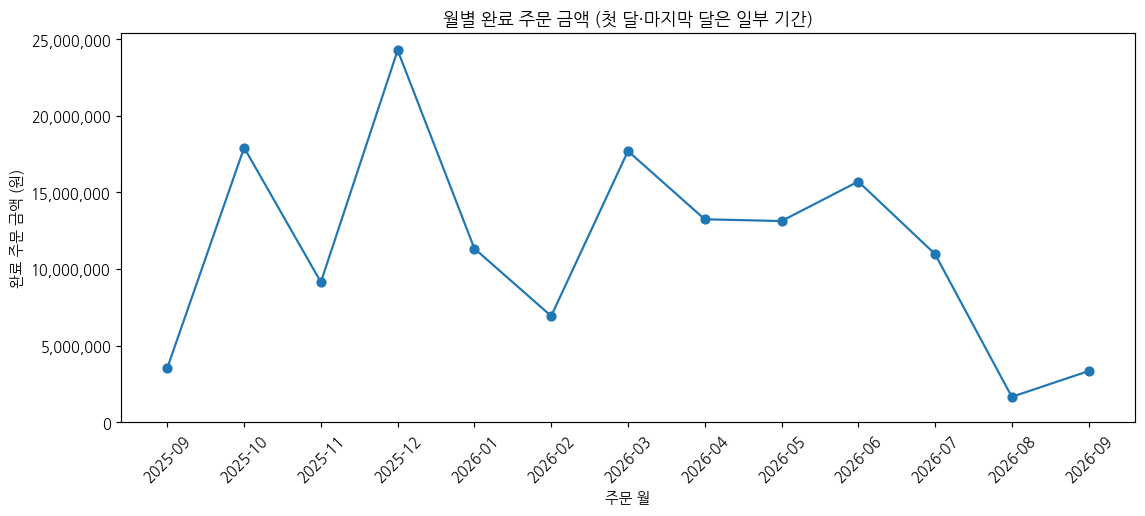

In [12]:
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(monthly_sales['order_month'],monthly_sales['total_sales'],marker='o')
ax.set(title='월별 완료 주문 금액 (첫 달·마지막 달은 일부 기간)',xlabel='주문 월',ylabel='완료 주문 금액 (원)')
ax.yaxis.set_major_formatter(money_formatter)
ax.set_ylim(bottom=0)
ax.tick_params(axis='x',rotation=45)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'ch07_monthly_sales_line.png',dpi=140,bbox_inches='tight')
plt.show()

## 9. 상품 가격 분포 히스토그램

히스토그램은 숫자형 데이터가 어느 구간에 많이 몰려 있는지 보여줍니다. 상품 가격 분포를 보면 저가/중가/고가 상품이 어떻게 분포하는지 확인할 수 있습니다.


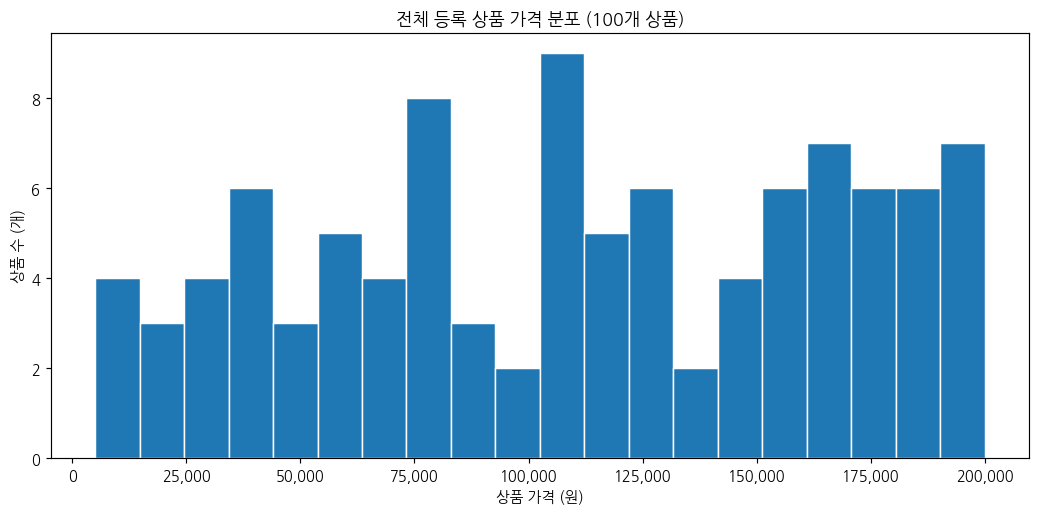

In [13]:
fig, ax = plt.subplots(figsize=(10,5))
ax.hist(products['price'].dropna(),bins=20,edgecolor='white')
ax.set(title='전체 등록 상품 가격 분포 (100개 상품)',xlabel='상품 가격 (원)',ylabel='상품 수 (개)')
ax.xaxis.set_major_formatter(money_formatter)
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'ch07_product_price_hist.png',dpi=140,bbox_inches='tight')
plt.show()

## 10. 상품 가격과 판매 수량 산점도

산점도는 두 숫자형 변수의 관계를 탐색할 때 사용합니다. 여기서는 상품 가격과 총 판매 수량 사이의 관계를 확인합니다. 산점도만으로 원인 관계를 단정해서는 안 됩니다.


Pearson 상관계수: -0.211
Spearman 상관계수: -0.241


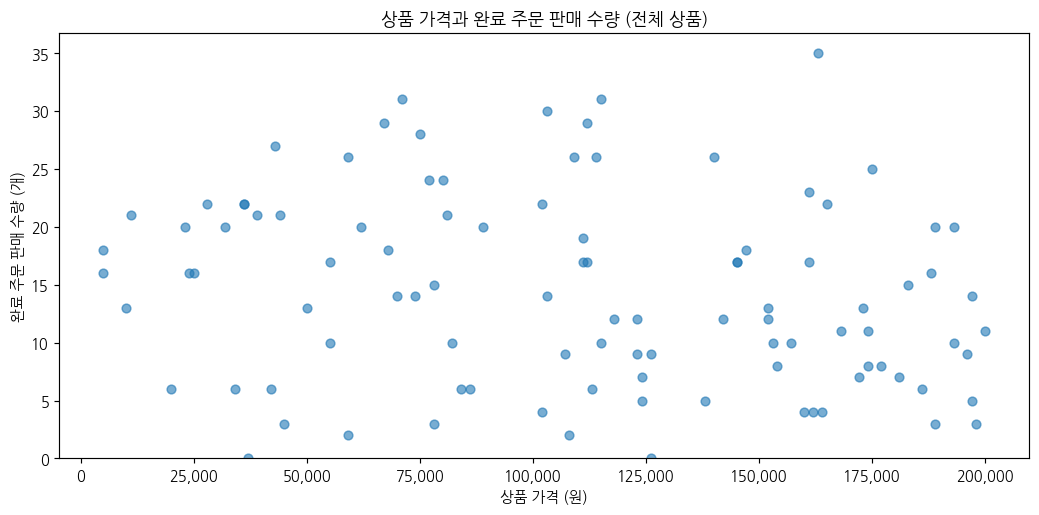

In [14]:
fig, ax = plt.subplots(figsize=(10,5))
ax.scatter(product_sales['price'],product_sales['completed_quantity'],alpha=.6)
ax.set(title='상품 가격과 완료 주문 판매 수량 (전체 상품)',xlabel='상품 가격 (원)',ylabel='완료 주문 판매 수량 (개)')
ax.xaxis.set_major_formatter(money_formatter)
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'ch07_price_quantity_scatter.png',dpi=140,bbox_inches='tight')
plt.show()
print('Pearson 상관계수:',round(product_sales['price'].corr(product_sales['completed_quantity']),3))
print('Spearman 상관계수:',round(product_sales['price'].corr(product_sales['completed_quantity'],method='spearman'),3))

## 11. 구매 금액 상위 고객 가로 막대그래프

상위 항목을 비교할 때는 가로 막대그래프가 읽기 좋습니다. 고객명은 개인정보가 될 수 있으므로 보고서에서는 익명화 라벨을 사용하는 것이 좋습니다.


고객별 구매 금액 상위 그래프는 우수 고객 후보를 확인하는 데 유용합니다. 하지만 한 번에 많이 구매한 고객과 여러 번 반복 구매한 고객은 구분해서 해석해야 합니다.


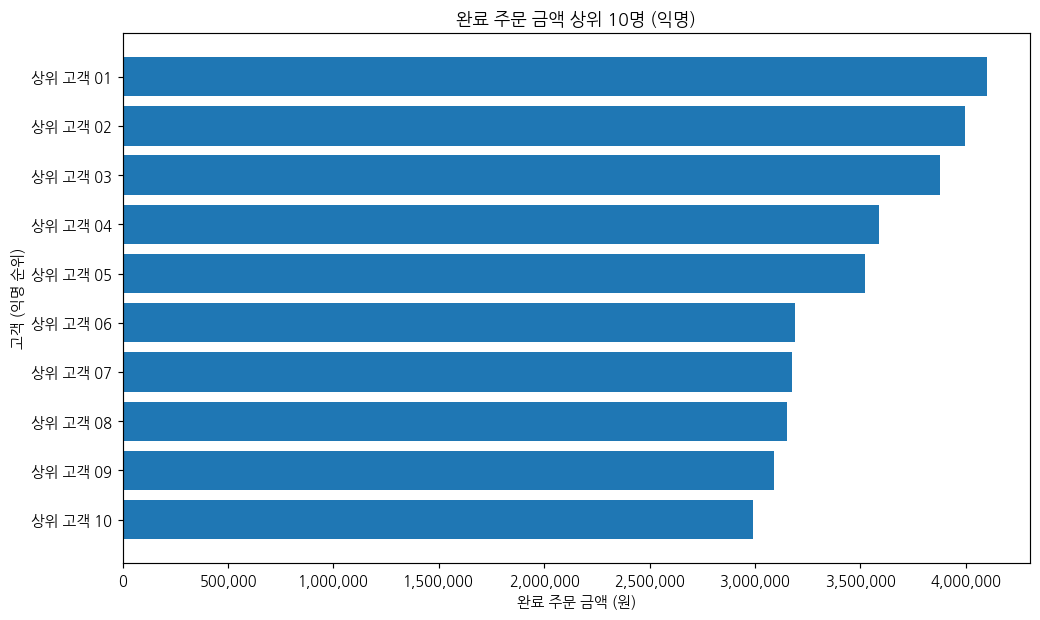

In [15]:
top_customers = customer_sales.head(10).copy().iloc[::-1].reset_index(drop=True)
# 고객 ID도 직접 노출하지 않고 순위와 번호만 표기한다.
top_customers['customer_label']=['상위 고객 '+str(i).zfill(2) for i in range(len(top_customers),0,-1)]
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(top_customers['customer_label'],top_customers['total_sales'])
ax.set(title='완료 주문 금액 상위 10명 (익명)',xlabel='완료 주문 금액 (원)',ylabel='고객 (익명 순위)')
ax.xaxis.set_major_formatter(money_formatter)
ax.set_xlim(left=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'ch07_top_customers_barh.png',dpi=140,bbox_inches='tight')
plt.show()

## 12. 주문 상태별 주문 수 막대그래프

주문 상태별 주문 수는 완료, 취소, 환불 등 주문 상태의 분포를 확인하는 데 사용합니다.


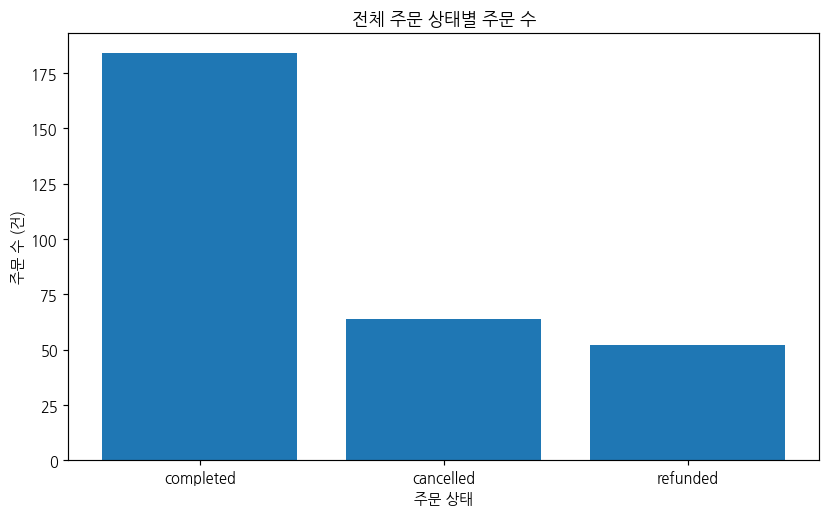

In [16]:
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(order_status['order_status'],order_status['order_count'])
ax.set(title='전체 주문 상태별 주문 수',xlabel='주문 상태',ylabel='주문 수 (건)')
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'ch07_order_status_bar.png',dpi=140,bbox_inches='tight')
plt.show()

## 13. 저장된 그래프 확인하기

생성된 그래프 파일을 확인합니다. 보고서나 발표 자료에 사용할 수 있도록 `reports/figures` 폴더에 저장했습니다.


In [17]:
list(FIGURE_DIR.glob('ch07_*.png'))


[PosixPath('/mnt/data/chapter07_실행패키지/reports/figures/ch07_category_sales_bar.png'), PosixPath('/mnt/data/chapter07_실행패키지/reports/figures/ch07_order_status_bar.png'), PosixPath('/mnt/data/chapter07_실행패키지/reports/figures/ch07_monthly_sales_line.png'), PosixPath('/mnt/data/chapter07_실행패키지/reports/figures/ch07_top_customers_barh.png'), PosixPath('/mnt/data/chapter07_실행패키지/reports/figures/ch07_product_price_hist.png'), PosixPath('/mnt/data/chapter07_실행패키지/reports/figures/ch07_price_quantity_scatter.png')]

## 14. 시각화 요약표 만들기

각 그래프의 목적과 해석 포인트를 표로 정리하면 이후 보고서 작성이 쉬워집니다.


In [18]:
visualization_summary = pd.DataFrame({
    'chart':['카테고리별 완료 주문 금액','월별 완료 주문 금액','상품 가격 분포','가격-완료 판매 수량 관계','완료 주문 상위 고객','주문 상태별 주문 수'],
    'range':['completed','completed','전체 상품','completed 판매 수량 + 전체 상품','completed','전체 주문'],
    'file_name':['ch07_category_sales_bar.png','ch07_monthly_sales_line.png','ch07_product_price_hist.png',
                 'ch07_price_quantity_scatter.png','ch07_top_customers_barh.png','ch07_order_status_bar.png'],
})
visualization_summary

,chart,range,file_name
0,카테고리별 완료 주문 금액,completed,ch07_category_sales_bar.png
1,월별 완료 주문 금액,completed,ch07_monthly_sales_line.png
2,상품 가격 분포,전체 상품,ch07_product_price_hist.png
3,가격-완료 판매 수량 관계,completed 판매 수량 + 전체 상품,ch07_price_quantity_scatter.png
4,완료 주문 상위 고객,completed,ch07_top_customers_barh.png
5,주문 상태별 주문 수,전체 주문,ch07_order_status_bar.png


## 15. 시각화 요약 보고서 저장하기

시각화 목적, 생성한 그래프 목록, 해석 포인트, 주의사항을 Markdown 보고서로 저장합니다.


In [19]:
summary_text = f'''# Chapter 07 시각화 집계 요약

- 금액성 범위: completed 주문만 사용
- 완료 주문: {completed_items['order_id'].nunique()}건, 상세 {len(completed_items)}행
- 원본 완료 주문 상세 합계: {source_total:,}원
- 카테고리별 합계: {category_sales['total_sales'].sum():,.0f}원
- 월별 합계: {monthly_sales['total_sales'].sum():,.0f}원
- 고객별 합계: {customer_sales['total_sales'].sum():,.0f}원
- 주문 기간: {orders['order_date'].min().date()} ~ {orders['order_date'].max().date()}
- 상품 가격 히스토그램: 전체 등록 상품 {len(products)}개 대상

## 그래프 목록

{visualization_summary.to_string(index=False)}

## 해석상의 주의

completed 상세 금액을 회계상 순매출로 보지 않는다. 월별 시계열 양 끝은 온전한 월이 아니다.
카테고리별 금액은 선호나 수익률을 뜻하지 않고, 산점도의 상관관계는 인과관계를 의미하지 않는다.
'''
summary_path=REPORT_DIR/'ch07_visualization_summary.md'
summary_path.write_text(summary_text,encoding='utf-8')
print('요약 보고서:',summary_path)

요약 보고서: /mnt/data/chapter07_실행패키지/reports/ch07_visualization_summary.md


## 16. 소스 모듈로 같은 시각화 실행하기

위에서 노트북으로 한 단계씩 실행한 시각화는 `src/visualization.py`에 함수로 정리되어 있습니다. 반복 실행하거나 프로젝트 코드로 관리하려면 소스 모듈을 사용하는 것이 좋습니다.


In [20]:
# 교재의 src.visualization 모듈이 첨부되지 않은 경우에도 본 노트북의 결과를 사용할 수 있다.
try:
    from src.visualization import (create_visualization_summary,prepare_visualization_data,setup_korean_font)
    print('src.visualization 모듈을 불러왔습니다.')
    # 모듈과 현재 노트북의 completed 범위가 같은지 확인하기 전에는 결과를 섞지 않는다.
except ImportError:
    print('교재의 src.visualization 모듈은 없어 노트북 결과를 그대로 사용합니다.')
module_viz_summary=visualization_summary.copy()
module_viz_summary

교재의 src.visualization 모듈은 없어 노트북 결과를 그대로 사용합니다.


,chart,range,file_name
0,카테고리별 완료 주문 금액,completed,ch07_category_sales_bar.png
1,월별 완료 주문 금액,completed,ch07_monthly_sales_line.png
2,상품 가격 분포,전체 상품,ch07_product_price_hist.png
3,가격-완료 판매 수량 관계,completed 판매 수량 + 전체 상품,ch07_price_quantity_scatter.png
4,완료 주문 상위 고객,completed,ch07_top_customers_barh.png
5,주문 상태별 주문 수,전체 주문,ch07_order_status_bar.png


## 17. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 시각화 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/run_visualization.py
```

이 스크립트는 7장 그래프 파일 6개와 `reports/ch07_visualization_summary.md`를 자동으로 저장합니다.


## 18. LLM에게 그래프 선택과 해석 요청하기

LLM은 그래프 선택, matplotlib 코드 작성, 해석 문장 작성에 도움을 줄 수 있습니다. 하지만 그래프 해석은 반드시 실제 데이터와 비교해야 합니다.

```text
온라인 쇼핑몰 데이터에서 다음 분석 질문을 시각화하려고 합니다.

분석 질문:
1. 카테고리별 매출은 어떻게 다른가?
2. 월별 매출은 어떻게 변하는가?
3. 상품 가격은 어떤 구간에 몰려 있는가?
4. 상품 가격과 판매 수량은 관계가 있는가?
5. 구매 금액 상위 고객은 누구인가?

각 질문에 적합한 그래프 종류를 추천해 주세요.
각 그래프를 선택한 이유와 주의할 점도 함께 설명해 주세요.
```


## 19. 그래프 해석 요청 예시

그래프 해석을 요청할 때는 데이터에 없는 원인을 단정하지 말라는 조건을 넣는 것이 좋습니다.

```text
다음은 카테고리별 매출 그래프를 만들기 위한 요약 데이터입니다.

category,total_sales,sales_ratio
전자기기,12500000,42.5
생활용품,7800000,26.5
패션,6200000,21.1
식품,2900000,9.9

이 그래프를 보고서에 넣을 수 있도록 해석 문장을 작성해 주세요.

조건:
- 데이터에 없는 원인을 단정하지 말 것
- 관찰 결과와 원인 가설을 구분할 것
- 추가로 확인해야 할 분석 질문을 제안할 것
- 초보자도 이해할 수 있게 작성할 것
```


## 20. 시각화 점검 체크리스트

그래프를 보고서에 넣기 전에 아래 항목을 점검합니다.

| 점검 항목 | 확인 |
|---|---|
| 분석 질문에 맞는 그래프를 선택했는가? | V |
| 그래프 제목이 명확한가? | V |
| x축과 y축 이름을 표시했는가? | V |
| 필요한 경우 단위를 표시했는가? | V |
| 범주형 데이터가 읽기 좋은 순서로 정렬되었는가? | V |
| 시간 데이터가 올바른 순서로 정렬되었는가? | V |
| 한글 폰트가 깨지지 않는가? | V |
| 그래프 해석에서 관찰과 원인을 구분했는가? | V |
| 개인정보가 필요한 경우 익명화했는가? | V |
| 그래프 파일을 저장했는가? | V |


## 21. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.
2. 결제수단별 주문 수 막대그래프를 그려 보세요.
3. 고객 나이 분포 히스토그램을 그려 보세요.
4. 월별 주문 수 선 그래프를 그려 보세요.
5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요.
6. 위 그래프 중 2개를 `reports/figures` 폴더에 저장하세요.


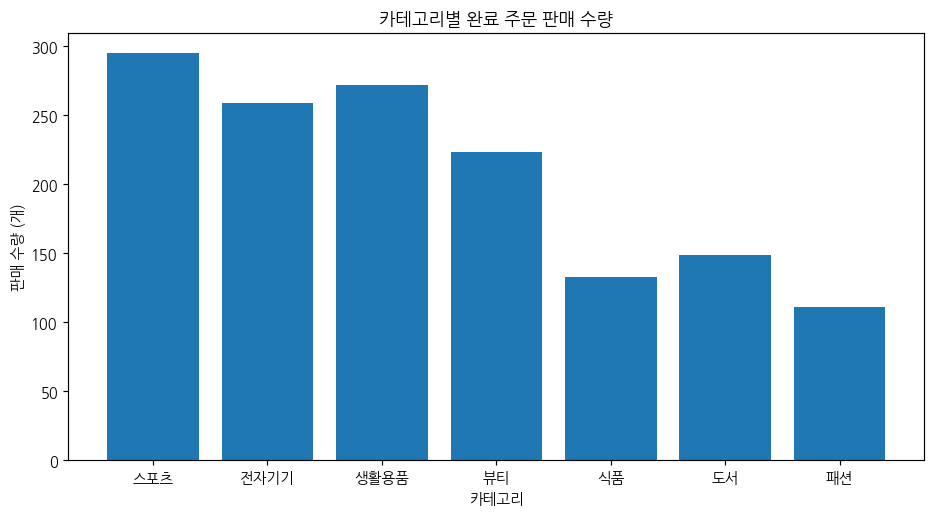

In [21]:
# 과제 1. 완료 주문 기준 카테고리별 판매 수량 비교
fig,ax=plt.subplots(figsize=(9,5))
ax.bar(category_sales['category'],category_sales['total_quantity'])
ax.set(title='카테고리별 완료 주문 판매 수량',xlabel='카테고리',ylabel='판매 수량 (개)')
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

payment_method
kakao_pay        79
naver_pay        77
bank_transfer    74
card             70
Name: count, dtype: int64


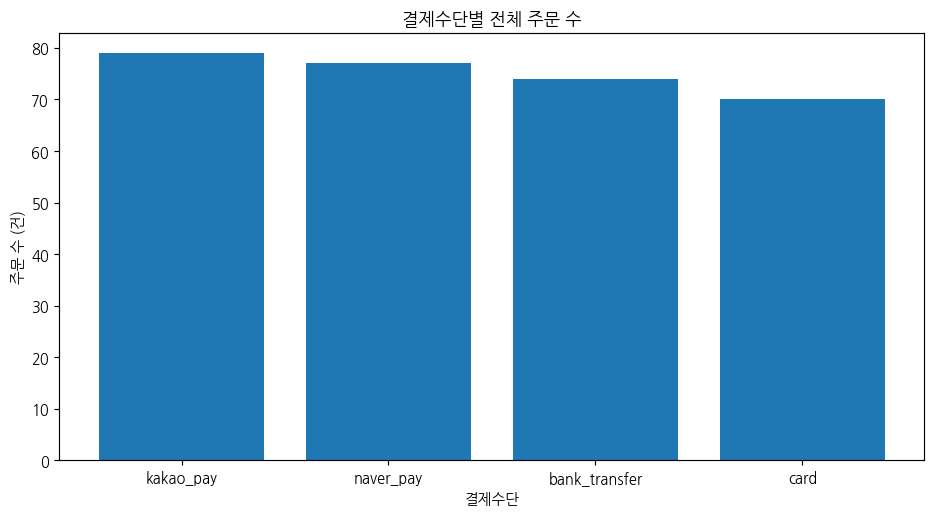

In [22]:
# 과제 2. 결제수단별 전체 주문 수 (주문 상세를 병합하지 않는다)
payment_counts=orders['payment_method'].value_counts(dropna=False)
fig,ax=plt.subplots(figsize=(9,5))
ax.bar(payment_counts.index.astype(str),payment_counts.values)
ax.set(title='결제수단별 전체 주문 수',xlabel='결제수단',ylabel='주문 수 (건)')
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()
print(payment_counts)

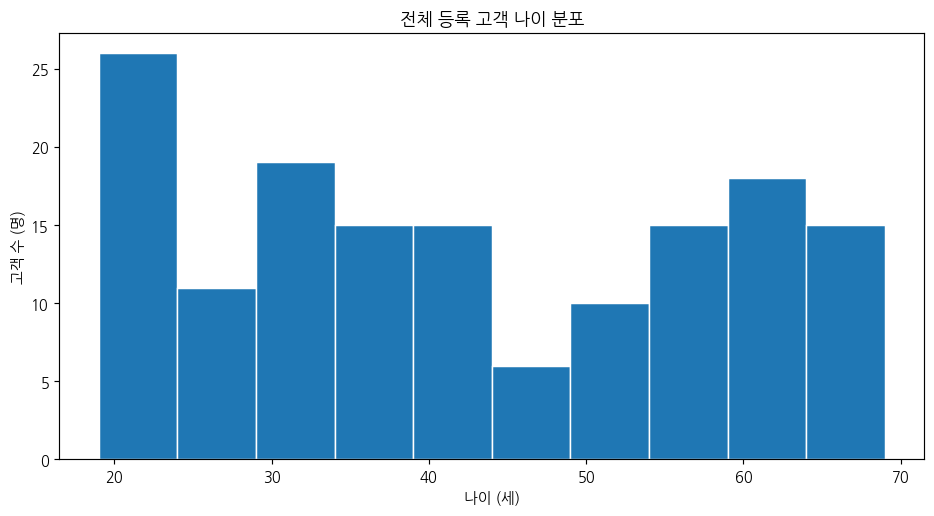

In [23]:
# 과제 3. 고객 나이 분포
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(customers['age'].dropna(),bins=10,edgecolor='white')
ax.set(title='전체 등록 고객 나이 분포',xlabel='나이 (세)',ylabel='고객 수 (명)')
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

## 22. 정리

이번 장에서는 다음 내용을 실습했습니다.

- 분석 질문에 맞는 그래프 선택
- matplotlib 기본 구조와 한글 폰트 설정
- 시각화를 위한 집계 데이터 준비
- 카테고리별 매출 막대그래프
- 월별 매출 선 그래프
- 상품 가격 분포 히스토그램
- 상품 가격과 판매 수량 산점도
- 구매 금액 상위 고객 가로 막대그래프와 익명화
- 주문 상태별 주문 수 막대그래프
- 그래프 파일 저장과 시각화 요약 보고서 작성
- `src/visualization.py`와 `scripts/run_visualization.py`로 반복 실행 가능한 구조 만들기

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.


# Chapter 07 답안 양식. 그래프로 데이터의 이야기를 보여주기

## 제출 정보
- 이름: 진민승
- GitHub ID: Jinminseung
- 작성일: 2026.10.26
- 최종 Notebook URL: https://github.com/Jinminseung/llm-data-analysis-study/blob/main/chapter07.ipynb

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 주문 금액은 어떻게 다른가? | 막대그래프 | 카테고리별 금액과 순위를 비교하기 위한 질문이기 때문이다. |
| 월별 completed 주문 금액은 어떻게 변하는가? | 선그래프 | 월의 시간 순서를 유지한 채 증가와 감소를 확인할 수 있기 때문이다. |
| 전체 등록 상품의 가격은 어떤 분포를 보이는가? | 히스토그램 | 개별 상품 가격을 구간별로 묶어 분포를 살펴보는 것이 목적이기 때문이다. |
금액에 관한 두 질문은 `completed` 주문만 사용하고, 가격 분포는 주문 상태와 상관없이 전체 등록 상품 100개를 사용하였다. 카테고리와 월별 금액을 그래프로 그리기 전에 집계표를 먼저 만들고 동일한 원본 합계와 일치하는지도 확인하였다. 특히 상품 가격 분포를 completed 판매 상품으로 제한하면 판매되지 않은 상품이 빠지므로 다른 범위로 구분했다.

In [24]:
# 과제에 사용할 세 그래프의 데이터 범위를 먼저 확인한다.
chart_specs = pd.DataFrame([
    {'질문':'카테고리별 완료 주문 금액','데이터 범위':'completed 주문 상세','지표':'카테고리별 line_total 합계','그래프':'막대그래프'},
    {'질문':'월별 완료 주문 금액','데이터 범위':'completed 주문 상세','지표':'월별 line_total 합계','그래프':'선그래프'},
    {'질문':'전체 등록 상품 가격 분포','데이터 범위':'전체 등록 상품','지표':'상품별 price','그래프':'히스토그램'},
])
print(chart_specs.to_string(index=False))
print('완료 주문:',completed_items['order_id'].nunique(),'건 / 전체 상품:',len(products),'개')

            질문          데이터 범위                  지표   그래프
카테고리별 완료 주문 금액 completed 주문 상세 카테고리별 line_total 합계 막대그래프
   월별 완료 주문 금액 completed 주문 상세    월별 line_total 합계  선그래프
전체 등록 상품 가격 분포        전체 등록 상품           상품별 price 히스토그램
완료 주문: 184 건 / 전체 상품: 100 개


## 2. 대표 그래프 1
카테고리별 completed 주문 금액 막대그래프

![대표 그래프 1](images/graph01.png)
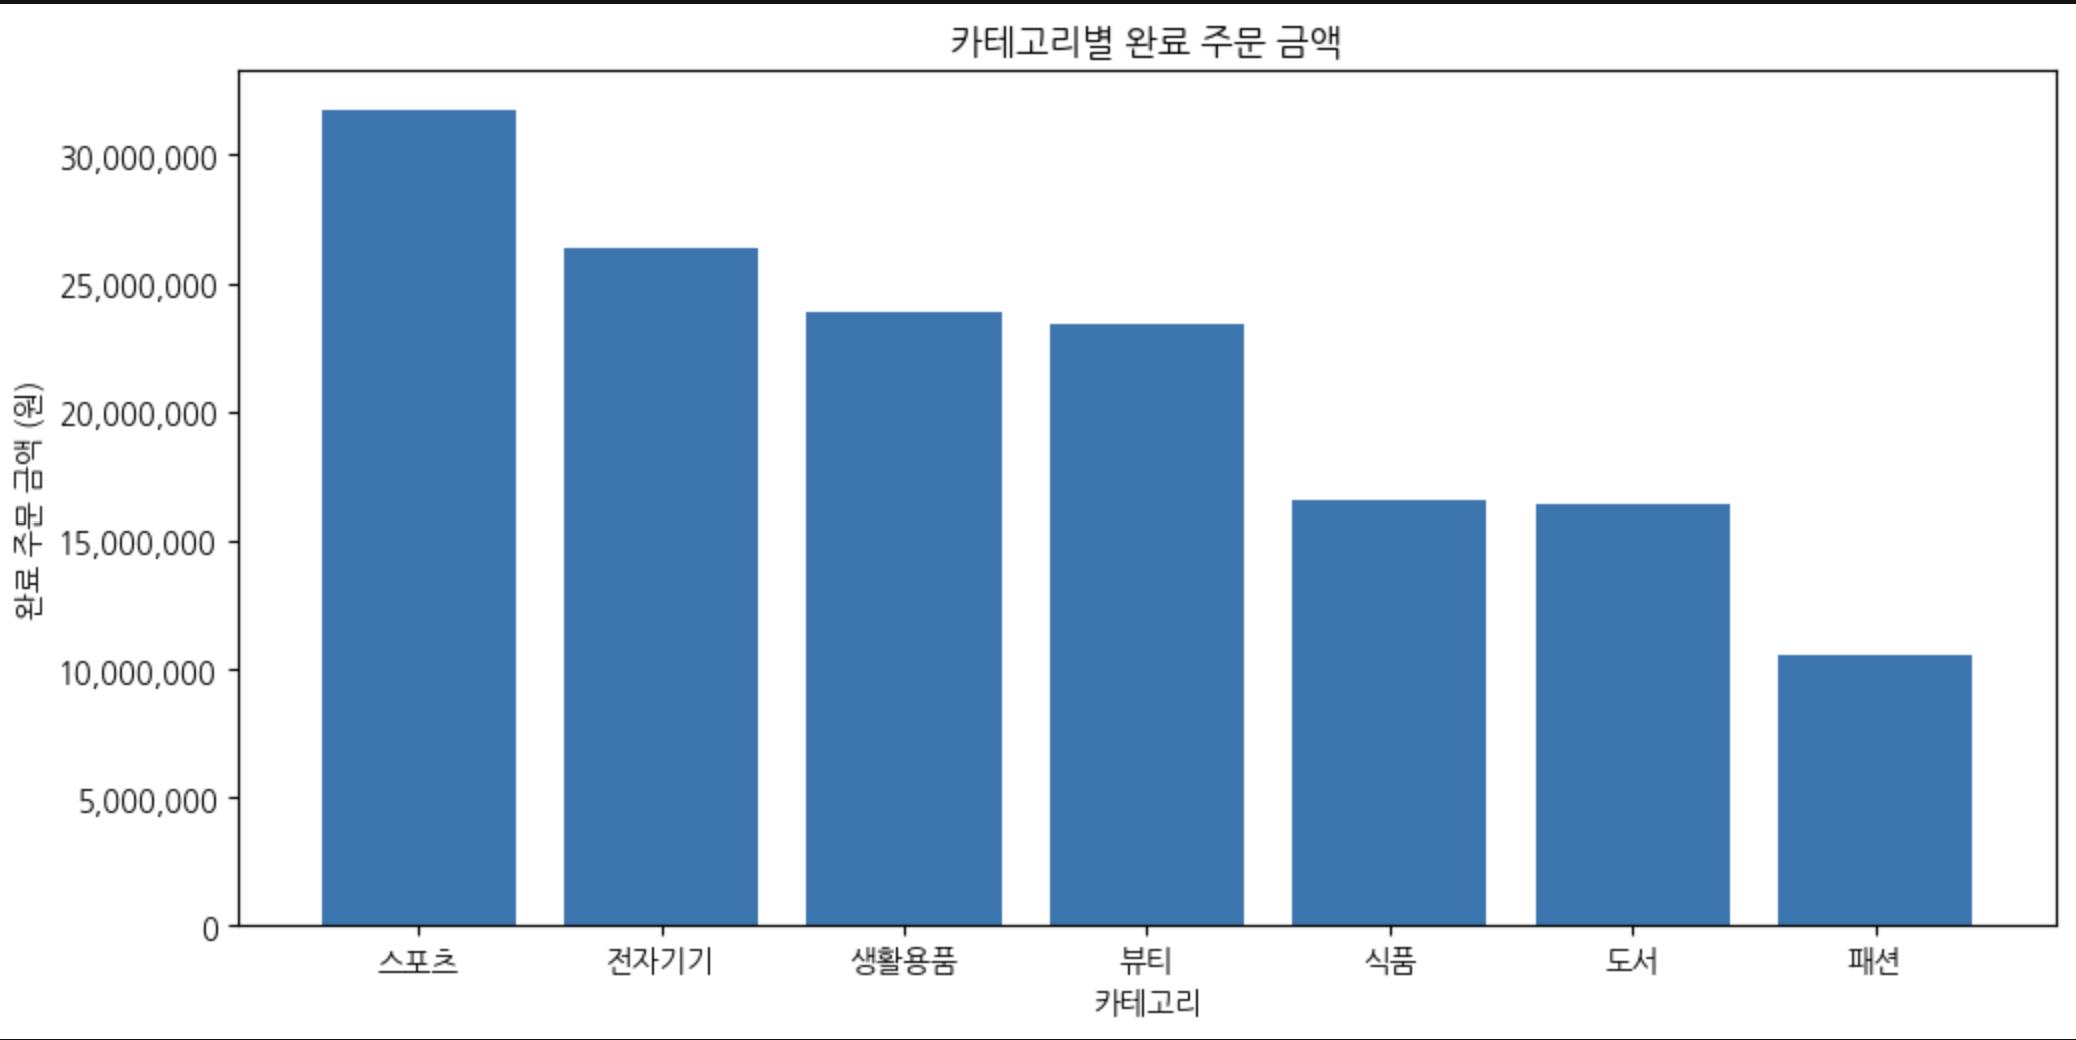

### 원본 집계값
완료 주문 184건의 상세 474행을 기준으로 한 금액 합계는 148,990,000원이다. 스포츠 31,743,000원(21.31%), 전자기기 26,400,000원(17.72%), 생활용품 23,915,000원(16.05%), 뷰티 23,383,000원(15.69%), 식품 16,573,000원(11.12%), 도서 16,389,000원(11.00%), 패션 10,587,000원(7.11%) 순이었다. 카테고리별 합계도 148,990,000원으로 원본과 일치했다.

### 결과 관찰
스포츠 카테고리의 완료 주문 금액이 가장 높았고 패션은 가장 낮았다. 스포츠와 패션의 금액 차이는 21,156,000원이었다. 스포츠 판매 수량은 295개로 비교적 많았지만, 금액의 차이를 판매 수량 하나로만 설명할 수는 없다.

### 나의 해석과 판단
금액이 큰 카테고리를 먼저 확인할 수 있다는 점에서 막대그래프가 적절하다고 판단했다. 다만 현재 금액은 판매 수량과 주문 시점의 단가가 함께 반영된 결과이기 때문에, 금액이 크다는 이유만으로 고객이 해당 카테고리를 더 선호한다고 보기는 어렵다.

### 업무·분석적 의미
카테고리별 금액 기여도를 확인하면 어떤 상품군의 상세 분석을 먼저 할지 정하는 데 참고할 수 있다. 스포츠처럼 금액이 높은 카테고리는 상품별 판매 수량과 주문 단가를 함께 비교할 필요가 있다.

### 한계와 추가 확인 사항
여기서 매출이라고 부르는 금액은 완료 주문의 `line_total` 합계이며 할인, 환불의 정산 여부, 원가와 배송비를 반영한 순매출이나 이익이 아니다. 다음에는 카테고리별 판매 수량, 평균 주문 단가, 상품 수를 비교하고 특정 상품에 금액이 집중되어 있는지도 확인하고자 한다.

category  total_quantity  total_sales  sales_ratio
     스포츠             295     31743000    21.305457
    전자기기             259     26400000    17.719310
    생활용품             272     23915000    16.051413
      뷰티             223     23383000    15.694342
      식품             133     16573000    11.123565
      도서             149     16389000    11.000067
      패션             111     10587000     7.105846


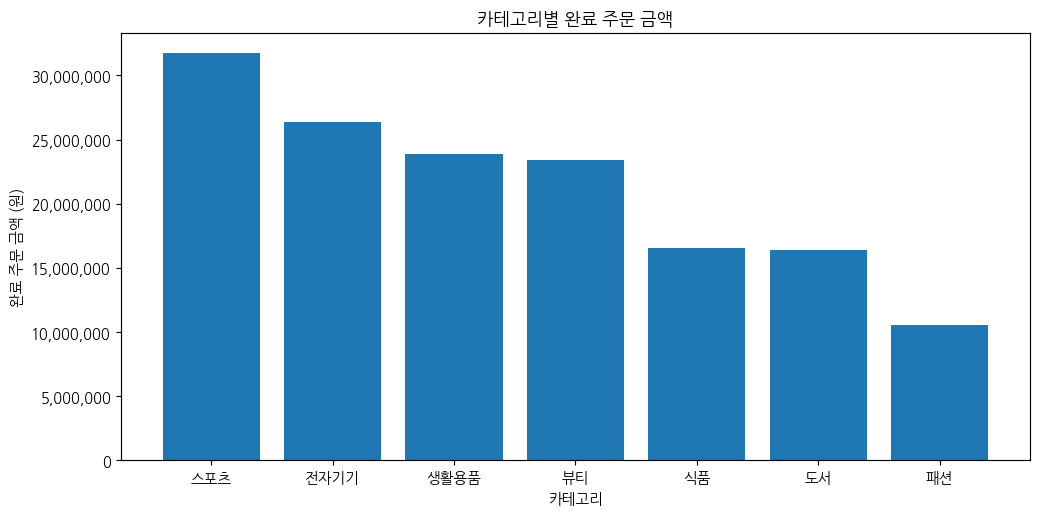

In [25]:
# 대표 그래프 1. 집계표를 먼저 확인하고 동일한 값으로 막대를 그린다.
print(category_sales[['category','total_quantity','total_sales','sales_ratio']].to_string(index=False))
assert np.isclose(category_sales.total_sales.sum(),source_total)
fig, ax = plt.subplots(figsize=(10,5))
rects=ax.bar(category_sales['category'],category_sales['total_sales'])
ax.set(title='카테고리별 완료 주문 금액',xlabel='카테고리',ylabel='완료 주문 금액 (원)')
ax.yaxis.set_major_formatter(money_formatter)
ax.set_ylim(bottom=0)
for rect,val in zip(rects,category_sales['total_sales']):
    assert np.isclose(rect.get_height(),val), '그래프 막대와 원본 금액 불일치'
fig.tight_layout()
fig.savefig(FIGURE_DIR/'graph01.png',dpi=140,bbox_inches='tight')
plt.show()

## 3. 대표 그래프 2
월별 completed 주문 금액 선그래프

![대표 그래프 2](images/graph02.png)
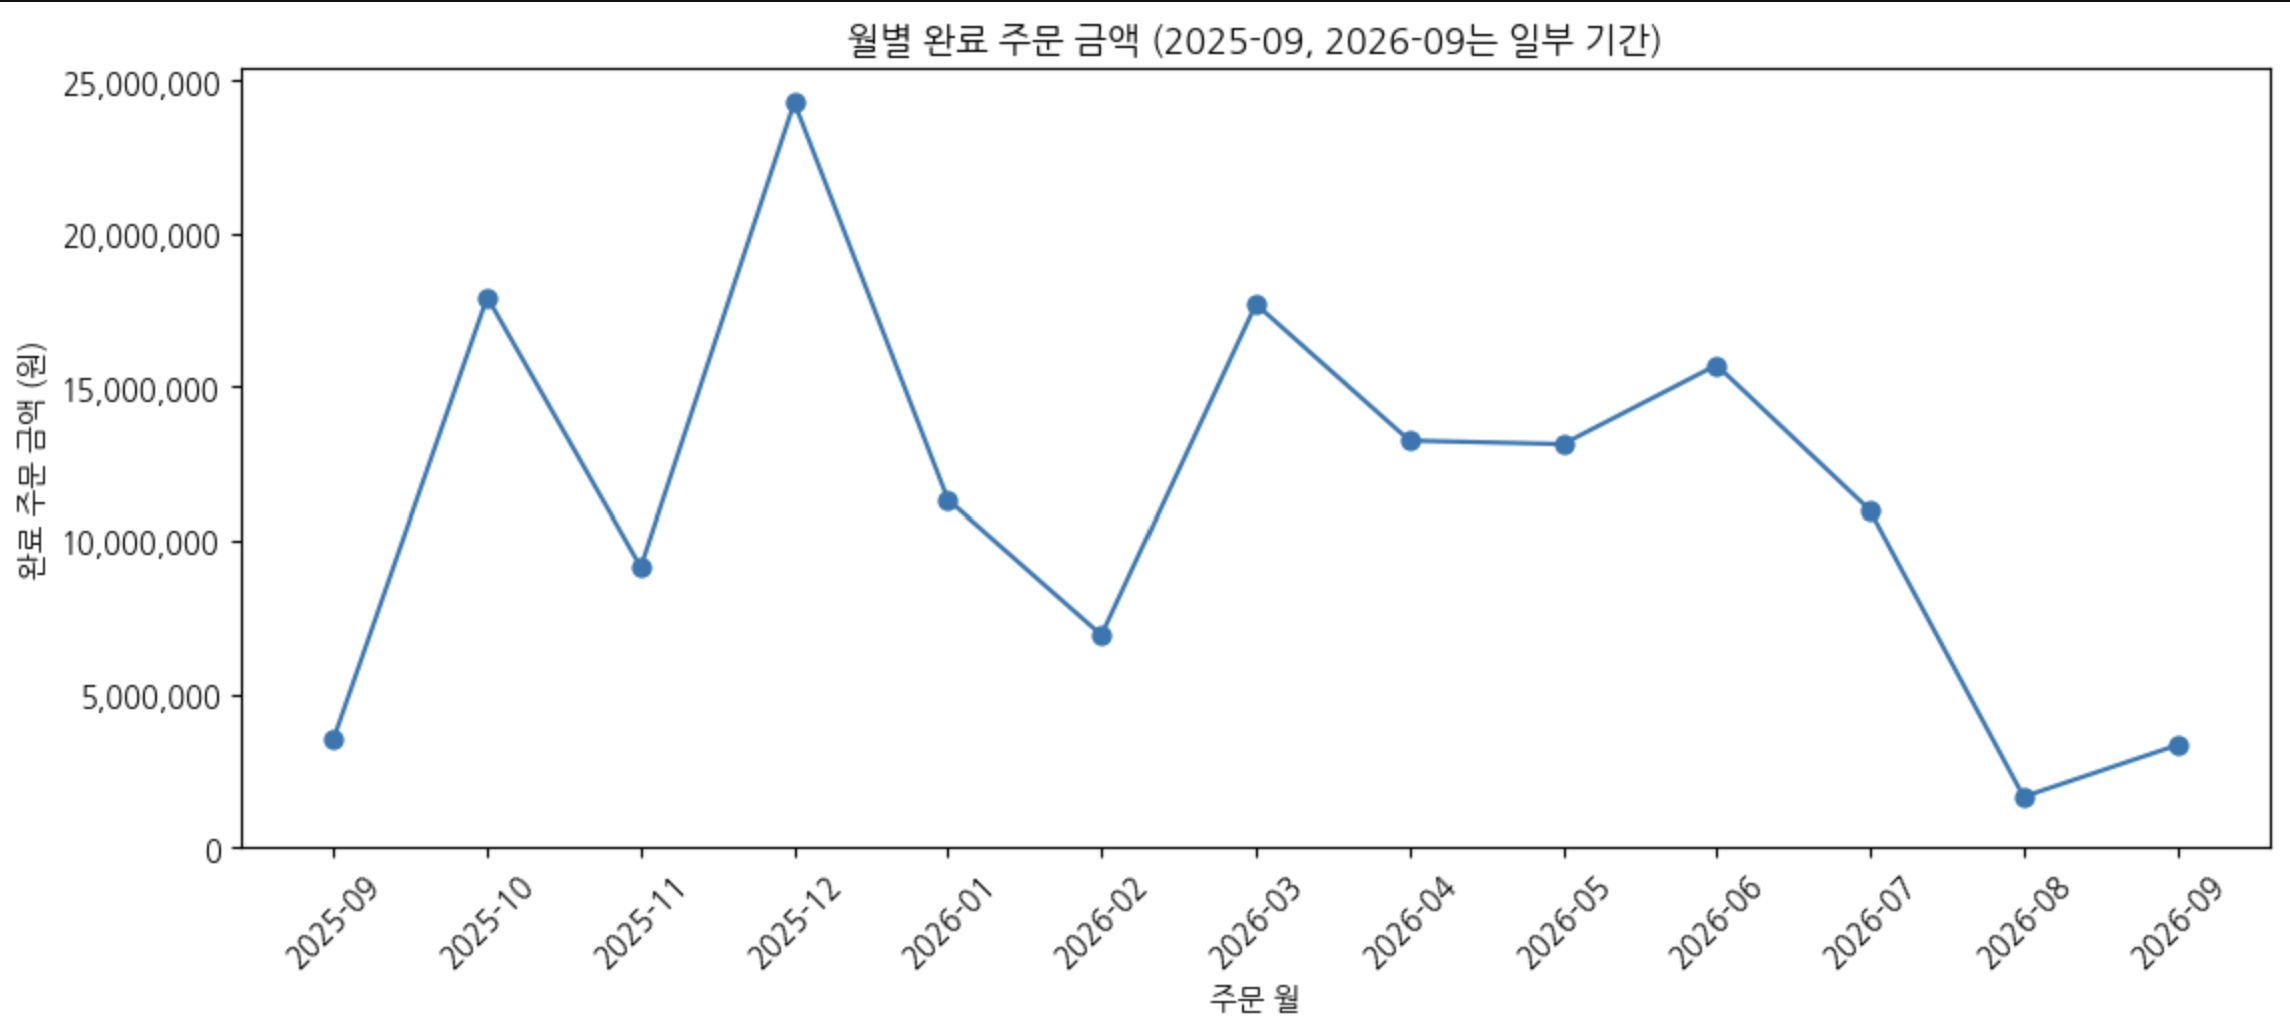

### 원본 집계값
2025년 9월부터 2026년 9월까지 월별 completed 주문 상세의 금액을 합산했다. 총합은 148,990,000원이며 월별 집계의 합계도 같았다. 가장 높은 달은 2025년 12월 24,278,000원(완료 주문 25건)이었고, 가장 낮은 달은 2026년 8월 1,666,000원(3건)이었다. 주문 날짜의 전체 범위는 2025년 9월 12일~2026년 9월 11일이다.

### 결과 관찰
2025년 12월의 완료 주문 금액은 다른 달보다 컸고, 이후에도 월마다 차이가 있었다. 2026년 8월에는 금액과 완료 주문 수가 모두 낮았다. 하지만 시계열에서 가장 처음과 마지막 월은 수집된 날짜가 월 전체를 포함하지 않는다.

### 나의 해석과 판단
월별 금액만 그리면 한 달의 주문 수가 많아서 금액이 높은 것인지, 주문 한 건당 금액이 커서 그런 것인지 구분하기 어렵다. 따라서 월별 주문 수와 평균 주문 금액을 함께 확인하는 것이 필요하다고 생각한다. 특히 2025년 9월과 2026년 9월은 월 일부만 포함되어 다른 월과 단순 비교하기 어렵다.

### 업무·분석적 의미
월별 금액이 크게 달라지는 시기를 찾은 뒤 주문 수와 평균 주문 금액 중 어느 지표가 변했는지 살펴볼 수 있다. 이를 통해 추가 분석이 필요한 달과 카테고리를 선정할 수 있다.

### 한계와 추가 확인 사항
이 데이터가 전체 거래를 빠짐없이 포함하는지 알 수 없고 광고, 프로모션, 재고 등의 정보도 없다. 금액이 변한 원인을 그래프만으로 판단하기 어렵다. 다음에는 월별 완료 주문 수와 평균 주문 금액을 분리하고, 같은 달의 카테고리별 금액까지 확인해보고자 한다.

order_month  order_count  total_sales  avg_order_value
    2025-09            6      3565000     5.941667e+05
    2025-10           20     17925000     8.962500e+05
    2025-11           11      9151000     8.319091e+05
    2025-12           25     24278000     9.711200e+05
    2026-01           15     11339000     7.559333e+05
    2026-02            9      6939000     7.710000e+05
    2026-03           23     17700000     7.695652e+05
    2026-04           20     13250000     6.625000e+05
    2026-05           14     13135000     9.382143e+05
    2026-06           20     15713000     7.856500e+05
    2026-07           15     10981000     7.320667e+05
    2026-08            3      1666000     5.553333e+05
    2026-09            3      3348000     1.116000e+06


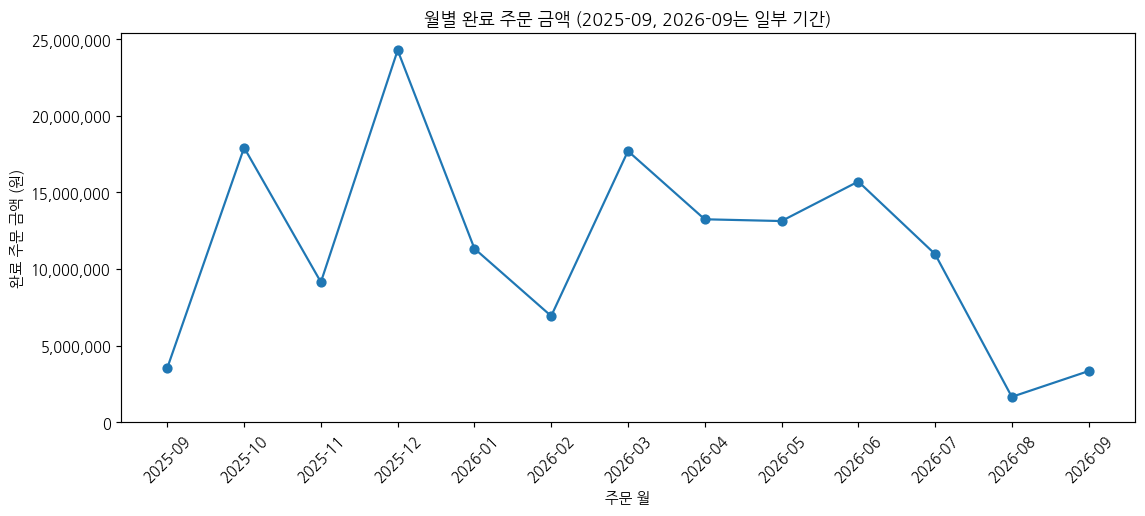

In [26]:
# 대표 그래프 2. 월별 원본 집계표를 확인한 다음 동일한 순서로 그린다.
print(monthly_sales[['order_month','order_count','total_sales','avg_order_value']].to_string(index=False))
assert monthly_sales.order_month.is_monotonic_increasing
assert np.isclose(monthly_sales.total_sales.sum(),source_total)
fig,ax=plt.subplots(figsize=(11,5))
line,=ax.plot(monthly_sales.order_month,monthly_sales.total_sales,marker='o')
ax.set(title='월별 완료 주문 금액 (2025-09, 2026-09는 일부 기간)',xlabel='주문 월',ylabel='완료 주문 금액 (원)')
ax.yaxis.set_major_formatter(money_formatter)
ax.set_ylim(bottom=0)
ax.tick_params(axis='x',rotation=45)
assert np.allclose(line.get_ydata(),monthly_sales.total_sales.to_numpy())
fig.tight_layout()
fig.savefig(FIGURE_DIR/'graph02.png',dpi=140,bbox_inches='tight')
plt.show()

## 4. 대표 그래프 3
전체 등록 상품 가격 히스토그램

![대표 그래프 3](images/graph03.png)
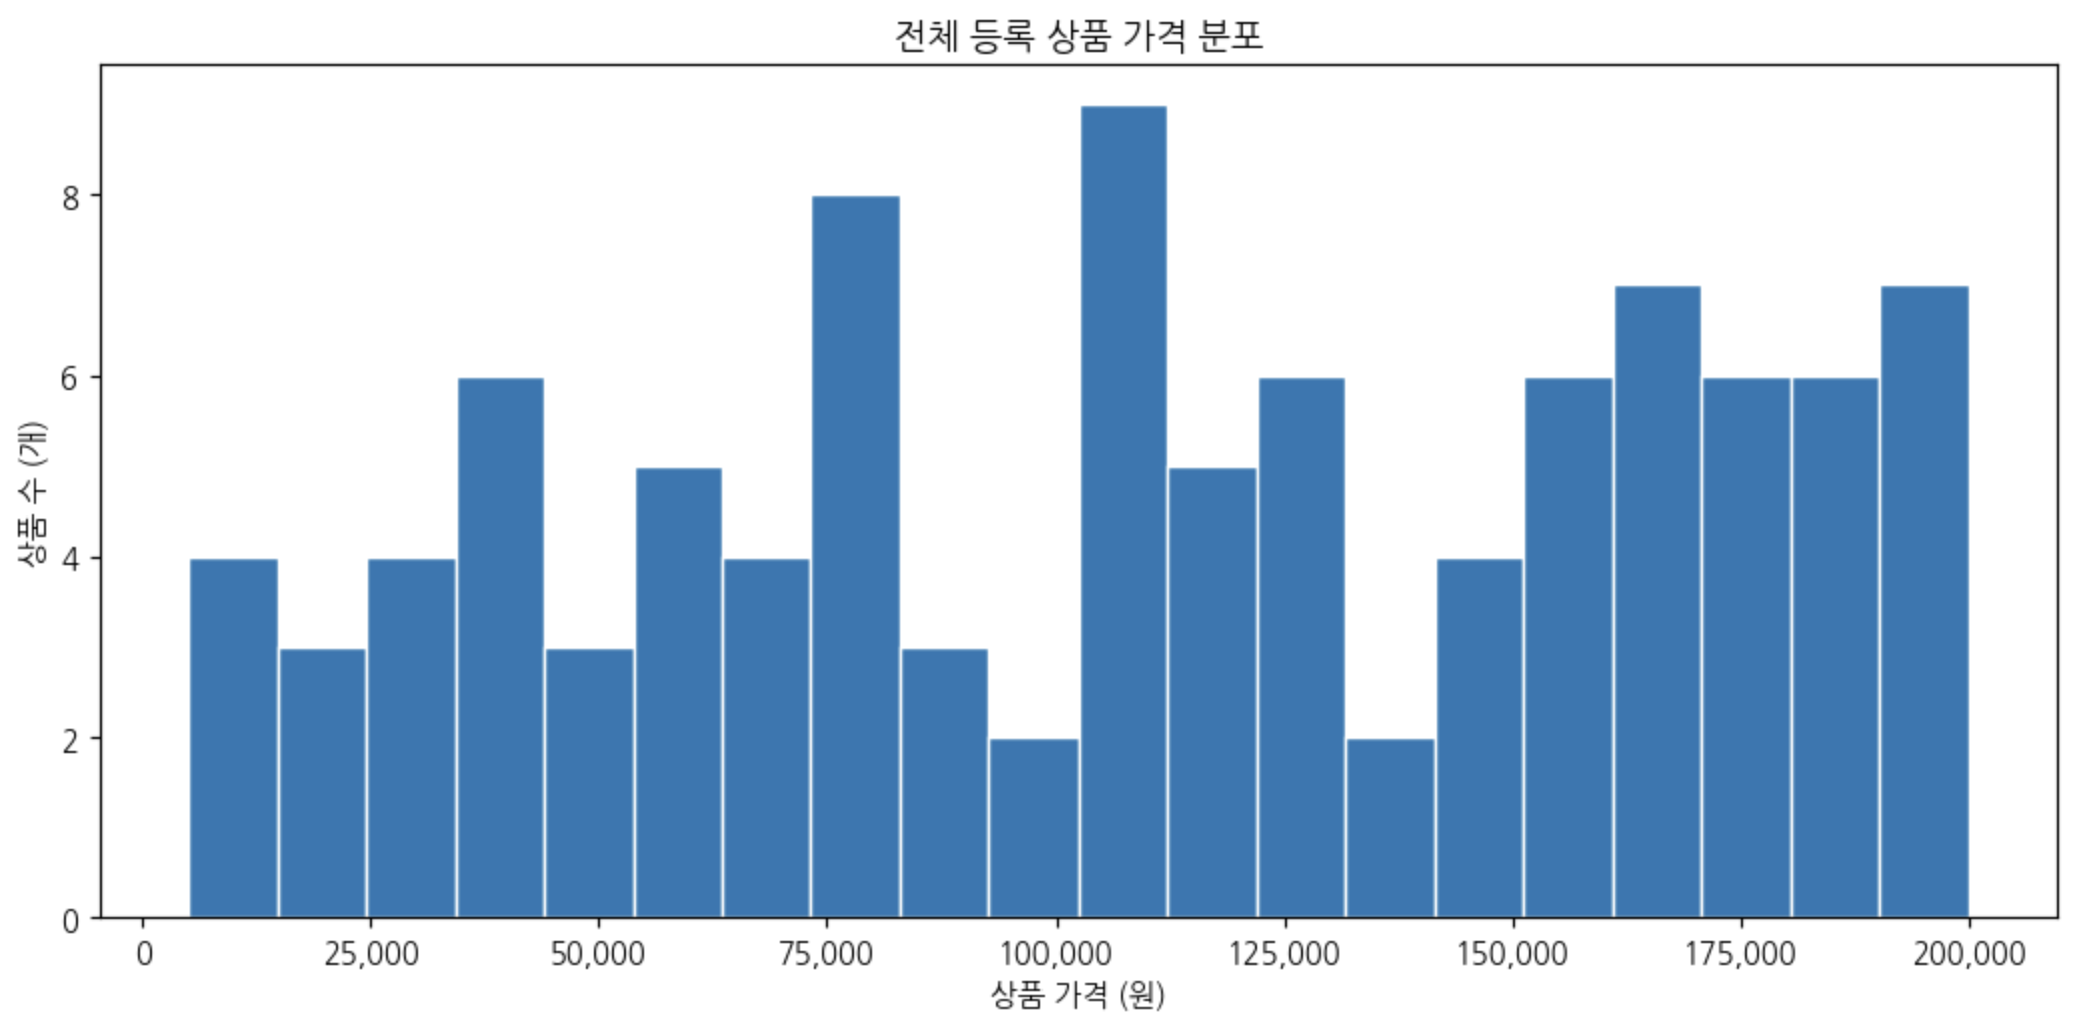

### 원본 집계값
상품 100개의 `price`를 사용했다. 최솟값은 5,000원, 최댓값은 200,000원, 평균은 110,040원, 중앙값은 112,000원, 제1사분위수는 65,750원, 제3사분위수는 161,000원이다. 그래프 구간 수는 20개로 설정했고, 다른 구간 수도 함께 확인하도록 코드를 작성했다.

### 결과 관찰
상품 가격이 한 가지 값에만 몰려 있지는 않았고, 5,000원부터 200,000원까지 비교적 넓은 범위에 분포했다. 10만 원 초과 15만 원 이하 상품은 28개, 15만 원 초과 20만 원 이하 상품은 32개였다. 평균과 중앙값 차이는 크지 않았다.

### 나의 해석과 판단
가격은 연속적인 숫자형 변수이므로 막대그래프보다는 히스토그램으로 구간별 분포를 확인하는 편이 적절했다. 다만 구간을 몇 개로 나누느냐에 따라 높이가 달라질 수 있으므로 특정 구간의 봉우리만 보고 분포 형태를 단정해서는 안 된다고 생각한다.

### 업무·분석적 의미
상품 가격대가 어느 정도까지 존재하는지 확인할 수 있으며, 카테고리별 금액을 해석할 때 가격 수준의 차이도 고려해야 한다는 점을 알 수 있다. 판매 수량이나 주문 금액만으로 상품 구성의 차이를 설명하기에는 부족하다.

### 한계와 추가 확인 사항
상품 마스터의 현재 가격과 실제 주문 당시 `unit_price`가 반드시 같다고 볼 수 없고, 상품별 판매 여부도 히스토그램에 반영되지 않는다. 가격 이상값을 자동으로 제외하기보다는 카테고리별 가격 분포 및 완료 주문 당시의 단가를 추가로 살펴보는 것이 필요하다.

상품 수: 100
count       100.000000
mean     110040.000000
std       56433.910574
min        5000.000000
25%       65750.000000
50%      112000.000000
75%      161000.000000
max      200000.000000
bins=10: 집계 상품 수 100개
bins=20: 집계 상품 수 100개
bins=30: 집계 상품 수 100개


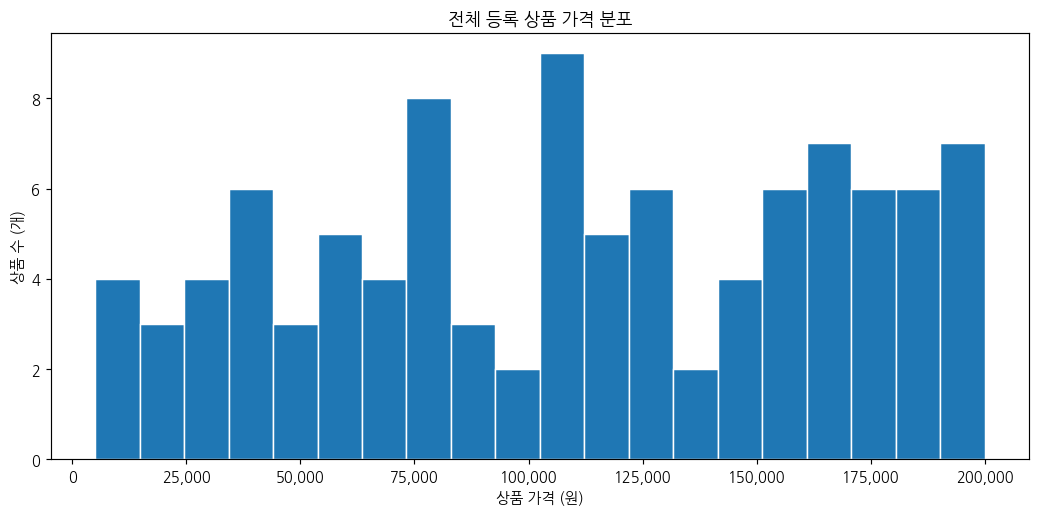

In [27]:
# 대표 그래프 3. 전체 상품 가격을 기준으로 히스토그램을 만든다.
print('상품 수:',len(products))
print(products['price'].describe().to_string())
for bins in (10,20,30):
    counts, edges=np.histogram(products.price.dropna(),bins=bins)
    assert counts.sum()==len(products), '히스토그램에 포함되지 않은 상품이 있습니다.'
    print(f'bins={bins}: 집계 상품 수 {counts.sum()}개')
fig,ax=plt.subplots(figsize=(10,5))
n,edges,rects=ax.hist(products.price.dropna(),bins=20,edgecolor='white')
assert n.sum()==len(products)
ax.set(title='전체 등록 상품 가격 분포',xlabel='상품 가격 (원)',ylabel='상품 수 (개)')
ax.xaxis.set_major_formatter(money_formatter)
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'graph03.png',dpi=140,bbox_inches='tight')
plt.show()

## 5. 그래프 정확성 점검
- [V] 그래프 값과 집계표 값 일치
- [V] 축 이름 확인
- [V] 단위 확인
- [V] 범례 확인 (단일 계열 그래프라 별도 범례가 필요하지 않음)
- [V] 날짜 정렬 확인
- [V] 과장될 수 있는 축 범위 확인
- [V] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점
처음 제공된 예제 코드에서는 카테고리별 금액과 월별 금액을 주문 상태와 관계없이 합산하는 부분이 있었다. 이 경우 취소·환불 주문까지 포함되어 완료 주문 금액을 설명하는 그래프와 범위가 달라지는 문제가 생긴다. 그래서 주문 정보를 먼저 연결한 후 `completed` 상태만 남기도록 수정했다. 병합 전후 상세 행 수와 매칭 여부를 확인하고 카테고리 및 월별 합계가 모두 원본 148,990,000원과 일치하는지도 검증하였다.
막대그래프는 값의 차이를 과장하지 않도록 금액 축을 0부터 시작하도록 했고, 축에 원 단위를 표시했다. 월별 그래프에서는 문자로 된 월을 실제 시간 순서로 정렬하고, 양 끝 달이 부분 기간이라는 사실을 제목과 해석에 적었다. 단일 계열 그래프에는 구분할 항목이 없어 범례를 별도로 추가하지 않았다. 히스토그램은 상품 100개가 빠짐없이 포함되는지 확인하고 구간 수를 바꿔 분포도 비교하였다.

In [28]:
# 모든 비교는 동일한 completed 주문 상세를 원본으로 한다.
check_totals=pd.DataFrame([
    ['completed 상세 원본',source_total],
    ['카테고리별 집계',category_sales.total_sales.sum()],
    ['월별 집계',monthly_sales.total_sales.sum()],
    ['고객별 집계',customer_sales.total_sales.sum()],
],columns=['집계 기준','금액 (원)'])
check_totals['원본 일치']=np.isclose(check_totals['금액 (원)'],source_total)
assert check_totals['원본 일치'].all()
assert len(status_items)==len(order_items)==764
assert len(sales_items)==len(completed_items)==474
assert monthly_sales.order_month.is_monotonic_increasing
assert products.price.notna().all()
# 대표 그래프의 파일 존재와 핵심 데이터도 검증한다.
for f in ['graph01.png','graph02.png','graph03.png']:
    assert (FIGURE_DIR/f).is_file(),f'{f} 저장 실패'
print(check_totals.to_string(index=False))
print('원본 / 카테고리 / 월별 / 고객 금액 합계: 모두 일치')
print('3개 그래프 저장 및 행 수 검증: 통과')

          집계 기준    금액 (원)  원본 일치
completed 상세 원본 148990000   True
       카테고리별 집계 148990000   True
          월별 집계 148990000   True
         고객별 집계 148990000   True
원본 / 카테고리 / 월별 / 고객 금액 합계: 모두 일치
3개 그래프 저장 및 행 수 검증: 통과


## 6. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유

카테고리별 completed 주문 금액 막대그래프가 가장 의미 있다고 생각한다. 질문이 명확하고 원본 집계값과의 비교가 쉬우며, 이후 상품군별 수량이나 단가 분석으로 연결하기 좋기 때문이다.

### 그래프가 보여 준 사실

전체 완료 주문 기준 금액 148,990,000원 가운데 스포츠 카테고리가 31,743,000원으로 가장 큰 비중을 차지했다. 패션과 비교하면 금액 차이가 상당했으며, 실제 카테고리 집계표와 그래프의 막대 높이도 일치했다.

### 그래프만으로 말할 수 없는 것

스포츠가 가장 수익성이 높은 카테고리인지, 고객이 가장 선호하는지, 마케팅 효과가 있었는지는 알 수 없다. 가격, 주문 수량, 원가와 재고, 구매 고객 수 같은 추가 정보가 필요하기 때문이다. 완료 주문 금액도 회계상 순매출로 단정해서는 안 된다.

### 다음 분석에서 확인할 질문

카테고리별 금액 차이는 상품 수, 판매 수량, 주문 당시 단가 중 어느 요인과 더 관련이 있는가? 이를 확인하기 위해 카테고리별 완료 주문 수량과 상품 수를 같이 보고, 상품별 금액 편중도 추가로 계산해 보고자 한다.

In [29]:
# 공개용 파일에는 고객 실명이나 직접 식별 정보를 저장하지 않는다.
# 최종 답안 그래프 3개를 다시 확인한다.
for filename in ['graph01.png','graph02.png','graph03.png']:
    path=FIGURE_DIR/filename
    print(filename, '저장 확인:',path.exists())
print('제출용 URL은 실제 GitHub 업로드 후 직접 입력한다.')

graph01.png 저장 확인: True
graph02.png 저장 확인: True
graph03.png 저장 확인: True
제출용 URL은 실제 GitHub 업로드 후 직접 입력한다.


## 최종 체크

- [V] 그래프와 수치를 교차 검증했습니다.
- [V] 관찰과 해석을 구분했습니다.
- [V] 업무적 의미와 한계를 작성했습니다.
- [V] 최종 Notebook URL을 입력할 항목을 남겼습니다. (실제 GitHub 업로드와 LMS 제출은 별도로 진행)